# Seminar 3.1: what does a CNN not care about?

People often say that CNNs are **translation invariant**: move the object around the image,
and the prediction stays the same. In this notebook we check that claim with three small
experiments:

1. **Shifting an image.** What happens to the output of a convolution when the input moves?
2. **Can a CNN tell top from bottom?** If CNNs were truly translation invariant, they could not.
3. **Rotating an image.** Convolutions know nothing about rotations. What can we do about it?

Sections 1 and 2 run on a laptop in under a minute. Section 3 trains two small CNNs on
CIFAR-10, which takes a few minutes on a GPU or Apple silicon.

In [12]:
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import Tensor, nn

torch.manual_seed(0)

# Use a GPU if there is one.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():  # Apple silicon
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("device:", DEVICE)

# Where CIFAR-10 is stored: the repo's data/ folder, or a local folder on Colab.
DATA = Path("../data") if Path("../train.py").exists() else Path("data")

device: mps


## 1. Shifting an image

Two words we will use throughout:

- A layer is **equivariant** to shifts if shifting the input shifts the output by the same
  amount. The output *moves along* with the input.
- A layer is **invariant** to shifts if shifting the input does not change the output at all.

Let's see what a convolution does. We draw a white square on a black image and convolve it
with a filter that detects vertical edges.

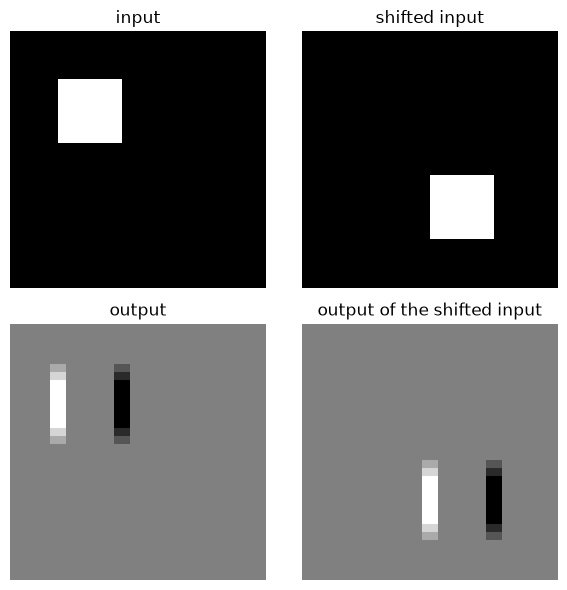

In [13]:
# A black 32×32 image with a white 8×8 square in it.
# Shape (1, 1, 32, 32): one image, one channel (grayscale).
image = torch.zeros(1, 1, 32, 32)
image[0, 0, 6:14, 6:14] = 1.0

# The same image, with the square moved 12 pixels down and 10 pixels to the right.
# torch.roll moves every pixel; pixels that fall off one side come back on the other.
shifted = torch.roll(image, shifts=(12, 10), dims=(2, 3))

# A 3×3 filter that responds to vertical edges: positive where the image gets brighter
# from left to right, negative where it gets darker.
edge_filter = torch.tensor([[-1.0, 0.0, 1.0],
                            [-1.0, 0.0, 1.0],
                            [-1.0, 0.0, 1.0]]).view(1, 1, 3, 3)  # fmt: skip

# Convolve both images with the same filter. padding=1 keeps the output 32×32.
out = F.conv2d(image, edge_filter, padding=1)
out_shifted = F.conv2d(shifted, edge_filter, padding=1)

# Plot the two inputs on top, the two outputs below.
fig, axes = plt.subplots(2, 2, figsize=(6, 6))
panels = [
    (image, "input"),
    (shifted, "shifted input"),
    (out, "output"),
    (out_shifted, "output of the shifted input"),
]
for ax, (img, title) in zip(axes.flat, panels, strict=True):
    ax.imshow(img[0, 0], cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

The edges in the output moved with the square. Let's check that this is exact: shifting the
output of the original image should give exactly the output of the shifted image.

In [14]:
# conv(shift(x)) versus shift(conv(x)): are they the same?
shift_then_conv = out_shifted
conv_then_shift = torch.roll(out, shifts=(12, 10), dims=(2, 3))
print("convolution is equivariant:", torch.allclose(shift_then_conv, conv_then_shift))

# Global max pooling keeps only the largest value of the whole map, wherever it is.
# So after pooling, the shift should be gone completely.
print("max of the output:              ", out.max().item())
print("max of the output, shifted input:", out_shifted.max().item())

convolution is equivariant: True
max of the output:               3.0
max of the output, shifted input: 3.0


So:

- a **convolution is equivariant**: the output moves along with the input;
- a **global pool** on top makes the network **invariant**: the position is thrown away.

That is where the claim "CNNs are translation invariant" comes from. But there is a catch.
Our square was far from the border. What happens near the edge of the image?

## 2. Can a CNN tell top from bottom?

If a CNN with a global pool were truly translation invariant, it could not know *where*
something is in the image. Let's test that with a task that is only about position.

Each image is black with one small white square, placed at random. The label is
**0 if the square is in the top half, 1 if it is in the bottom half**. Nothing else
distinguishes the two classes.

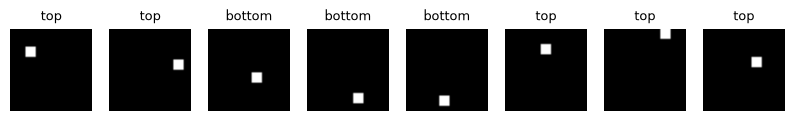

In [15]:
def make_squares(n: int, seed: int) -> tuple[Tensor, Tensor, Tensor]:
    """Make n images with one 4×4 white square each, at a random position.

    Returns the images (n, 1, 32, 32), the labels (n,) (0 = top half, 1 = bottom half) and
    the row of each square (n,), which we use later to see where the network makes mistakes.
    """
    generator = torch.Generator().manual_seed(seed)
    # Top-left corner of each square: anywhere such that the square fits in the image.
    rows = torch.randint(0, 29, (n,), generator=generator)
    cols = torch.randint(0, 29, (n,), generator=generator)

    images = torch.zeros(n, 1, 32, 32)
    for i in range(n):
        images[i, 0, rows[i] : rows[i] + 4, cols[i] : cols[i] + 4] = 1.0

    # The centre of the square is at row + 2. Below row 16 means the bottom half.
    labels = (rows + 2 >= 16).long()
    return images.to(DEVICE), labels.to(DEVICE), rows


train_x, train_y, _ = make_squares(4000, seed=0)
test_x, test_y, test_rows = make_squares(1000, seed=1)

# Show a few examples.
fig, axes = plt.subplots(1, 8, figsize=(10, 1.8))
for i, ax in enumerate(axes):
    ax.imshow(train_x[i, 0].cpu(), cmap="gray")
    ax.set_title("bottom" if train_y[i] == 1 else "top", fontsize=9)
    ax.axis("off")
plt.show()

The network: four 3×3 convolutions (the last three with stride 2, so the feature map
shrinks from 32×32 to 4×4), a **global max pool**, and a linear layer. The global pool
throws away where the strongest feature was.

We train it twice, changing only how the convolutions **pad** the border:

- `"zeros"`: the usual choice. The image is surrounded by a frame of zeros.
- `"circular"`: the image wraps around. The pixels outside the left edge are copied from
  the right edge, and the same for top and bottom. The image has no border at all.

In [16]:
def small_cnn(padding_mode: str) -> nn.Sequential:
    """Four 3×3 convolutions, a global max pool and a linear layer with 2 outputs."""
    return nn.Sequential(
        # (1, 32, 32) -> (16, 32, 32)
        nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1, padding_mode=padding_mode),
        nn.ReLU(),
        # (16, 32, 32) -> (32, 16, 16)
        nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1, padding_mode=padding_mode),
        nn.ReLU(),
        # (32, 16, 16) -> (32, 8, 8)
        nn.Conv2d(32, 32, kernel_size=3, stride=2, padding=1, padding_mode=padding_mode),
        nn.ReLU(),
        # (32, 8, 8) -> (32, 4, 4)
        nn.Conv2d(32, 32, kernel_size=3, stride=2, padding=1, padding_mode=padding_mode),
        nn.ReLU(),
        # Keep only the largest value of each channel: (32, 4, 4) -> (32,)
        nn.AdaptiveMaxPool2d(1),
        nn.Flatten(),
        # One score per class.
        nn.Linear(32, 2),
    )


def train(model: nn.Module, x: Tensor, y: Tensor, epochs: int = 20) -> nn.Module:
    """Train with Adam and the cross-entropy loss, in mini-batches of 100 images."""
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()
        # Visit the training images in a new random order every epoch.
        for batch in torch.randperm(len(x), device=DEVICE).split(100):
            loss = F.cross_entropy(model(x[batch]), y[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model


@torch.no_grad()
def predict(model: nn.Module, x: Tensor) -> Tensor:
    """The predicted class of every image."""
    model.eval()
    return model(x).argmax(dim=1)


models = {}
for padding_mode in ("zeros", "circular"):
    torch.manual_seed(0)
    models[padding_mode] = train(small_cnn(padding_mode), train_x, train_y)
    correct = predict(models[padding_mode], test_x) == test_y
    print(f"padding {padding_mode!r:>10}: test accuracy {100 * correct.float().mean():.1f}%")

padding    'zeros': test accuracy 82.4%
padding 'circular': test accuracy 53.6%


Chance is 50%. With **circular** padding the network stays close to chance: it really cannot
tell where the square is. With **zero** padding it does much better. So the network *does*
know where the square is, even though the global pool threw the position away.

Where does the position come from? Let's look at which squares the zero-padding network
gets right.

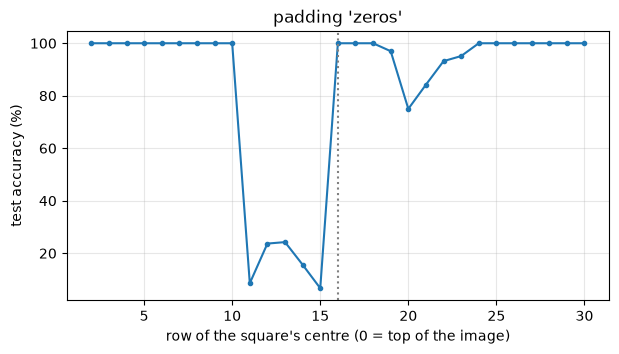

In [17]:
# Is the prediction right (1) or wrong (0), for every test image?
correct = (predict(models["zeros"], test_x) == test_y).cpu().float()

# Group the test images by the row of the square's centre, and average per row.
centre_rows = test_rows + 2
rows = range(2, 31)
accuracy_per_row = [100 * correct[centre_rows == r].mean() for r in rows]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rows, accuracy_per_row, marker=".")
ax.axvline(16, color="gray", ls=":")  # the line between the top and the bottom half
ax.set_xlabel("row of the square's centre (0 = top of the image)")
ax.set_ylabel("test accuracy (%)")
ax.set_title("padding 'zeros'")
ax.grid(alpha=0.3)
plt.show()

The network is always right when the square is **close to the top or the bottom edge**,
and it makes its mistakes in the middle of the image, far from both edges. So it uses the
**border**. Near the edge, part of what a filter sees is the zero padding, so a square there
produces different features than a square in the middle. After a few layers, the network
can tell how close something is to an edge, and to which edge. In the middle, that signal
is weak: a square just above the middle is far from the top edge, so the network calls it
"bottom" almost every time.

Circular padding removes the border, so the network has nothing to tell the positions apart.

**The takeaway.** "CNNs are translation invariant" is only true without borders. With
zero padding, which nearly every CNN uses, a CNN can and does learn *where* things are.
Usually that is harmless, sometimes useful. But if position happens to predict the label in
your training data, the network may learn the position instead of the object.

## 3. Rotating an image

Nothing in a convolution knows about rotations: a filter that detects a horizontal edge does
not detect a vertical one. So a CNN trained on upright images should struggle with rotated
ones. Let's test that on CIFAR-10, and try the simplest fix: **data augmentation**, that is,
rotating the training images.

To keep things simple we only rotate by multiples of 90° (`torch.rot90`), which moves
pixels around without blurring them.

train: (50000, 3, 32, 32)  test: (10000, 3, 32, 32)


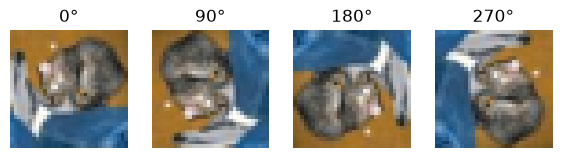

In [18]:
EPOCHS = 5  # per model; a few minutes on a GPU or Apple silicon

# Load CIFAR-10 and keep all images on the device as one tensor of uint8 (0-255).
cifar = datasets.load_dataset("uoft-cs/cifar10", cache_dir=str(DATA))


def to_tensors(split: datasets.Dataset) -> tuple[Tensor, Tensor]:
    """Convert a dataset split to images (N, 3, 32, 32) and labels (N,) on the device."""
    split = split.with_format("numpy")[:]
    images = torch.from_numpy(np.stack(split["img"]))  # (N, H, W, C)
    images = images.permute(0, 3, 1, 2).contiguous()  # channels first: (N, C, H, W)
    labels = torch.from_numpy(split["label"]).long()
    return images.to(DEVICE), labels.to(DEVICE)


cifar_train_x, cifar_train_y = to_tensors(cifar["train"])
cifar_test_x, cifar_test_y = to_tensors(cifar["test"])
print("train:", tuple(cifar_train_x.shape), " test:", tuple(cifar_test_x.shape))

# The same test image, rotated by 0°, 90°, 180° and 270°.
fig, axes = plt.subplots(1, 4, figsize=(7, 2))
for k, ax in enumerate(axes):
    rotated = torch.rot90(cifar_test_x[0], k, dims=(1, 2))  # k quarter turns
    ax.imshow(rotated.permute(1, 2, 0).cpu())  # back to (H, W, C) for plotting
    ax.set_title(f"{90 * k}°")
    ax.axis("off")
plt.show()

The model is a small CNN with batch norm, like the ones in seminar 3. The only difference
between the two runs is the `augment` flag: with augmentation, every training batch is
rotated by a random multiple of 90°.

In [19]:
def conv_block(c_in: int, c_out: int) -> list[nn.Module]:
    """A 3×3 convolution, batch norm and ReLU."""
    return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU()]


def cifar_cnn() -> nn.Sequential:
    """Three stages of two conv blocks, with max pooling between them, then a classifier."""
    return nn.Sequential(
        *conv_block(3, 32), *conv_block(32, 32), nn.MaxPool2d(2),     # 32×32 -> 16×16
        *conv_block(32, 64), *conv_block(64, 64), nn.MaxPool2d(2),    # 16×16 -> 8×8
        *conv_block(64, 128), *conv_block(128, 128),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),                        # global average pool
        nn.Linear(128, 10),                                           # one score per class
    )  # fmt: skip


def normalize(images: Tensor) -> Tensor:
    """uint8 images (0-255) -> floats between -1 and 1."""
    return images.float() / 127.5 - 1


def train_cifar(model: nn.Module, augment: bool, epochs: int = EPOCHS) -> nn.Module:
    """Train with Adam in batches of 256. If augment, rotate each batch by k × 90°."""
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        for batch in torch.randperm(len(cifar_train_x), device=DEVICE).split(256):
            images = normalize(cifar_train_x[batch])
            if augment:
                k = int(torch.randint(0, 4, ()))  # 0, 1, 2 or 3 quarter turns
                images = torch.rot90(images, k, dims=(2, 3))
            loss = F.cross_entropy(model(images), cifar_train_y[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f"  epoch {epoch + 1}/{epochs}, last batch loss {loss.item():.2f}")
    return model


@torch.no_grad()
def rotated_accuracy(model: nn.Module, k: int) -> float:
    """Test accuracy (%) when every test image is rotated by k × 90°."""
    model.eval()
    correct = 0
    for batch in torch.arange(len(cifar_test_x), device=DEVICE).split(1000):
        images = torch.rot90(normalize(cifar_test_x[batch]), k, dims=(2, 3))
        correct += (model(images).argmax(dim=1) == cifar_test_y[batch]).sum().item()
    return 100 * correct / len(cifar_test_x)


cifar_models = {}
for name, augment in (("no augmentation", False), ("rotation augmentation", True)):
    print(name)
    torch.manual_seed(0)
    cifar_models[name] = train_cifar(cifar_cnn(), augment)

no augmentation
  epoch 1/5, last batch loss 1.13
  epoch 2/5, last batch loss 0.71
  epoch 3/5, last batch loss 0.73
  epoch 4/5, last batch loss 0.74
  epoch 5/5, last batch loss 0.80
rotation augmentation
  epoch 1/5, last batch loss 1.53
  epoch 2/5, last batch loss 1.12
  epoch 3/5, last batch loss 1.32
  epoch 4/5, last batch loss 1.01
  epoch 5/5, last batch loss 1.25


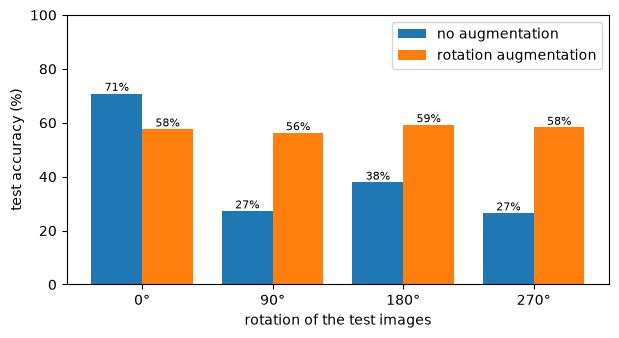

In [20]:
# Evaluate both models on the test set, rotated by 0°, 90°, 180° and 270°.
angles = [0, 90, 180, 270]
fig, ax = plt.subplots(figsize=(7, 3.5))
width = 35  # width of the bars, in degrees
for i, (name, model) in enumerate(cifar_models.items()):
    accuracies = [rotated_accuracy(model, k) for k in range(4)]
    positions = [a + (i - 0.5) * width for a in angles]  # put the two bars side by side
    bars = ax.bar(positions, accuracies, width=width, label=name)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
ax.set_xticks(angles, [f"{a}°" for a in angles])
ax.set_xlabel("rotation of the test images")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 100)
ax.legend()
plt.show()

Chance is 10%.

- **Without augmentation**, the network does well on upright images but loses more than half
  of its accuracy on rotated ones. It learned what objects look like *the right way up*.
- **With rotation augmentation**, the accuracy is about the same for every rotation. But on
  upright images it is clearly worse than the first network: with the same size and the same
  training time, it has to learn every class in four orientations instead of one.

So invariance to rotations is not free. Augmentation teaches it, but the network pays for it
with accuracy on the images it would normally see. Whether that is worth it depends on the
data. CIFAR-10 photos are almost always upright, so here it probably isn't.

## Questions to think about

1. In section 2, try `padding_mode="reflect"` or `"replicate"`. Do they behave like zeros or
   like circular? Why? (Hint: what does a white square look like next to each kind of
   padding?)
2. In section 2, make the network deeper, or remove the strides. How does that change the
   accuracy-per-row plot?
3. In section 3, which classes lose the most accuracy at 0° when we add rotation
   augmentation? Can you think of datasets where you *do* want rotation invariance
   (satellite images, microscopy), and ones where you don't (think of the digits 6 and 9)?